# sic2 coverage and within-permno fill

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
s = pl.scan_parquet(CHARS_PARQUET).select("permno", "DATE", "sic2").collect().sort("permno", "DATE")
per = s.group_by("permno").agg(pl.len().alias("rows"), pl.col("sic2").is_null().sum().alias("missing"),
                               pl.col("sic2").drop_nulls().n_unique().alias("distinct_codes"))
pl.DataFrame({
    "rows": [s.height], "rows_missing": [s["sic2"].null_count()],
    "permnos": [per.height], "permnos_with_any_missing": [(per["missing"] > 0).sum()],
    "permnos_never_observed": [(per["missing"] == per["rows"]).sum()],
    "rows_in_never_observed_permnos": [per.filter(pl.col("missing") == pl.col("rows"))["rows"].sum()],
    "permnos_with_code_change": [(per["distinct_codes"] > 1).sum()],
})

rows,rows_missing,permnos,permnos_with_any_missing,permnos_never_observed,rows_in_never_observed_permnos,permnos_with_code_change
i64,i64,i64,i64,i64,i64,i64
2383384,16779,22523,2372,845,13101,128


## Rows still missing after each fill step

In [3]:
f = s.with_columns(pl.col("sic2").forward_fill().over("permno").alias("ffill"))
f = f.with_columns(pl.col("ffill").backward_fill().over("permno").alias("ffill_bfill"))
pl.DataFrame({"step": ["raw", "ffill", "ffill + bfill"],
              "rows_missing": [f["sic2"].null_count(), f["ffill"].null_count(), f["ffill_bfill"].null_count()]})

step,rows_missing
str,i64
"""raw""",16779
"""ffill""",14728
"""ffill + bfill""",13101


## Position of missing rows within each permno's history

In [4]:
f = f.with_columns(pl.int_range(pl.len()).over("permno").alias("pos"), pl.len().over("permno").alias("n"))
f.filter(pl.col("sic2").is_null() & pl.col("ffill_bfill").is_not_null()).select(
    gap_rows=pl.len(), first_row=(pl.col("pos") == 0).mean(), last_row=(pl.col("pos") == pl.col("n") - 1).mean(),
    in_1990=(pl.col("DATE") < 19910101).mean())

gap_rows,first_row,last_row,in_1990
u32,f64,f64,f64
3678,0.0179,0.3972,0.0701


## Missing sic2 by year

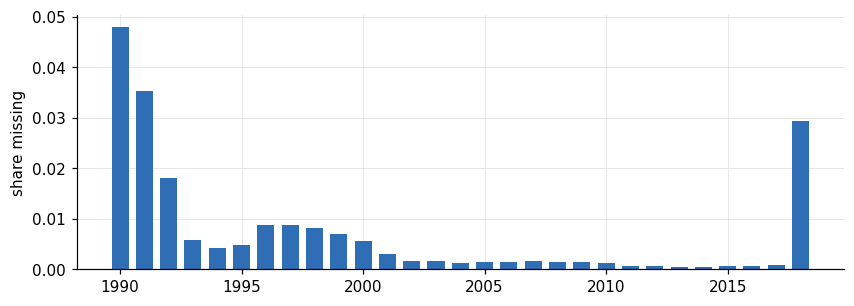

In [5]:
y = s.group_by((pl.col("DATE") // 10000).alias("year")).agg(pl.col("sic2").is_null().mean().alias("missing")).sort("year")
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(y["year"], y["missing"], color=BLUE, width=0.7); ax.set_ylabel("share missing"); plt.show()